# Лабораторная работа 3. N-граммы, RNN-LM и динамика градиентов (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование

**Цель.** Построить baseline языкового моделирования и экспериментально увидеть, почему рекуррентные модели уступили трансформерам: затухание и взрыв градиентов определяются спектром рекуррентного якобиана.

**Что нужно сдать:**
1. Символьную n-граммную модель с интерполированным сглаживанием Кнезера–Нея и perplexity для $n = 2\dots5$ (или $2\dots7$).
2. Ручной обратный проход для одного шага RNN, сверенный с autograd.
3. Графики норм градиента $\|\partial \mathcal{L}/\partial h_t\|$ в зависимости от расстояния до loss при разных спектральных радиусах $W_{hh}$.
4. Сравнительную таблицу n-gram, RNN, LSTM по perplexity и bits-per-byte.
5. График зависимости энтропии выходного распределения от температуры.

**Теория.** Для $h_t = \tanh(W_{hh}h_{t-1} + W_{xh}x_t + b)$:

$$\frac{\partial h_T}{\partial h_t} = \prod_{s=t+1}^{T} \operatorname{diag}\!\big(1 - h_s^2\big)\,W_{hh}, \qquad \Big\|\frac{\partial h_T}{\partial h_t}\Big\| \le \big(\gamma\,\sigma_{\max}(W_{hh})\big)^{T-t}$$

где $\gamma = \max |\tanh'| \le 1$. При $\gamma\sigma_{\max} < 1$ градиент затухает экспоненциально.


In [2]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.12.0.dev20260408+cu128, device=cuda, FAST_DEV_RUN=True


In [3]:
text = load_shakespeare()
n = len(text); train_text, val_text = text[: int(0.9 * n)], text[int(0.9 * n):]
if FAST_DEV_RUN: val_text = val_text[:20_000]
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; V = len(chars)
print(f"train={len(train_text):,}, val={len(val_text):,}, |V|={V}")

train=1,003,854, val=20,000, |V|=65


## 1. N-граммная модель с интерполированным Кнезером–Неем

Для контекста $h$ (последние $n-1$ символов) и его укороченной версии $h'$:

$$P_{KN}(w\mid h) = \frac{\max(c(h w) - D, 0)}{c(h)} + \frac{D\, N_{1+}(h\,\bullet)}{c(h)}\,P_{KN}(w\mid h').$$

На старшем уровне $c$ — обычные счётчики, на младших уровнях — **счётчики продолжения** $N_{1+}(\bullet\, h w)$ (число различных символов, предшествующих $hw$). Нижний уровень — интерполяция с равномерным распределением. Если $c(h) = 0$, используется только $P_{KN}(w\mid h')$.


In [4]:
from collections import Counter, defaultdict

class KneserNey:
    def __init__(self, order, D=0.75):
        self.order, self.D = order, D

    def fit(self, text):
        N = self.order
        self.counts = [Counter() for _ in range(N + 1)]       # counts[k][str длины k]
        # (старший уровень — обычные счётчики, младшие — число различных левых продолжений)
        
        # 1. Сбор n-грамм старшего уровня (абсолютные частоты)
        for i in range(len(text) - N + 1):
            ngram = text[i:i + N]
            self.counts[N][ngram] += 1
            
        # 2. Подсчет продолжений (continuation counts) для младших уровней (от N-1 до 1)
        for k in range(N - 1, 0, -1):
            for ngram_longer in self.counts[k + 1]:
                # Левое продолжение для текущей n-граммы — это её суффикс
                suffix = ngram_longer[1:] 
                self.counts[k][suffix] += 1
        
        # агрегаты по контекстам: сумма счётчиков и число различных продолжений
        self.ctx_total = [defaultdict(float) for _ in range(N + 1)]
        self.ctx_types = [defaultdict(int) for _ in range(N + 1)]
        for k in range(1, N + 1):
            for g, c in self.counts[k].items():
                self.ctx_total[k][g[:-1]] += c; self.ctx_types[k][g[:-1]] += 1
        self.V = len(set(text))
        return self

    def _prob(self, ctx, w, level):
        """Рекурсивная интерполированная KN.  ctx имеет длину level-1."""
        if level <= 0:
            return 1.0 / self.V
        g = ctx + w
        c_h = self.ctx_total[level].get(ctx, 0)
        if c_h == 0:
            # нет данных этого уровня — берём только укороченный контекст
            return self._prob(ctx[1:], w, level - 1) if ctx else 1.0 / self.V
        c_hw   = self.counts[level].get(g, 0)
        n1plus = self.ctx_types[level].get(ctx, 0)
        lam    = self.D * n1plus / c_h
        lower  = self._prob(ctx[1:], w, level - 1) if ctx else 1.0 / self.V
        return max(c_hw - self.D, 0.0) / c_h + lam * lower

    def prob(self, ctx, w):
        """P_KN(w | ctx); ctx — строка длины до order-1."""
        max_len = self.order - 1
        if len(ctx) > max_len:
            ctx = ctx[-max_len:]
        return self._prob(ctx, w, len(ctx) + 1)

    def cross_entropy(self, text):
        N = self.order; nll = 0.0
        for i in range(N - 1, len(text)):
            nll -= math.log(self.prob(text[i - N + 1:i], text[i]))
        return nll / (len(text) - N + 1)

# санити-чек: распределение нормировано
kn3 = KneserNey(3).fit(train_text)
s = sum(kn3.prob("th", c) for c in chars); print("сумма P(·|'th') =", round(s, 6)); assert abs(s - 1) < 1e-6
s = sum(kn3.prob("qz", c) for c in chars); print("сумма P(·|'qz') =", round(s, 6)); assert abs(s - 1) < 1e-6

сумма P(·|'th') = 1.0
сумма P(·|'qz') = 1.0


In [5]:
ngram_res = {}
for order in ([2, 3, 4, 5] if FAST_DEV_RUN else [2, 3, 4, 5, 6, 7]):
    t0 = time.time(); lm = KneserNey(order).fit(train_text); ce = lm.cross_entropy(val_text)
    ngram_res[order] = ce
    print(f"n={order}: CE={ce:.3f} нат, perplexity={math.exp(ce):.2f}, bpb={ce / math.log(2):.3f}  ({time.time() - t0:.0f} c)")

n=2: CE=2.492 нат, perplexity=12.09, bpb=3.596  (0 c)
n=3: CE=1.985 нат, perplexity=7.28, bpb=2.863  (0 c)
n=4: CE=1.662 нат, perplexity=5.27, bpb=2.397  (0 c)
n=5: CE=1.498 нат, perplexity=4.47, bpb=2.161  (0 c)


## 2. Ручной обратный проход одного шага RNN

Даны $x_t$, $h_{t-1}$ и градиент сверху $\delta = \partial\mathcal{L}/\partial h_t$. Выведите

$$\delta_a = \delta \odot (1 - h_t^2),\quad \frac{\partial\mathcal{L}}{\partial W_{hh}} = \delta_a^\top h_{t-1},\quad \frac{\partial\mathcal{L}}{\partial W_{xh}} = \delta_a^\top x_t,\quad \frac{\partial\mathcal{L}}{\partial b} = \textstyle\sum \delta_a,\quad \frac{\partial\mathcal{L}}{\partial h_{t-1}} = \delta_a W_{hh}$$

(для батча строк, $h_t = \tanh(h_{t-1}W_{hh}^\top + x_t W_{xh}^\top + b)$).


In [6]:
def rnn_step_forward(x, h_prev, Wxh, Whh, b):
    h = torch.tanh(x @ Wxh.T + h_prev @ Whh.T + b)
    return h, (x, h_prev, h)

def rnn_step_backward(dh, cache, Wxh, Whh):
    x, h_prev, h = cache
    dh_raw = dh * (1.0 - h * h)
    dWxh   = dh_raw.T @ x
    dWhh   = dh_raw.T @ h_prev
    db     = dh_raw.sum(dim=0)
    dx     = dh_raw @ Wxh
    dh_prev = dh_raw @ Whh
    return dx, dh_prev, dWxh, dWhh, db

torch.manual_seed(0)
Bz, Din, H = 4, 6, 5
x = torch.randn(Bz, Din, dtype=torch.float64, requires_grad=True); hp = torch.randn(Bz, H, dtype=torch.float64, requires_grad=True)
Wxh = torch.randn(H, Din, dtype=torch.float64, requires_grad=True); Whh = torch.randn(H, H, dtype=torch.float64, requires_grad=True)
b = torch.randn(H, dtype=torch.float64, requires_grad=True)
h, cache = rnn_step_forward(x, hp, Wxh, Whh, b)
dh = torch.randn_like(h); (h * dh).sum().backward()
ours = rnn_step_backward(dh, tuple(t.detach() for t in cache), Wxh.detach(), Whh.detach())
for name, a, ref in zip(["dx", "dh_prev", "dWxh", "dWhh", "db"], ours, [x.grad, hp.grad, Wxh.grad, Whh.grad, b.grad]):
    print(f"{name:8s} max|diff|={(a - ref).abs().max().item():.2e}"); assert torch.allclose(a, ref, atol=1e-10)

dx       max|diff|=0.00e+00
dh_prev  max|diff|=0.00e+00
dWxh     max|diff|=0.00e+00
dWhh     max|diff|=0.00e+00
db       max|diff|=0.00e+00


## 3. Затухание и взрыв градиентов

Возьмите необученную RNN со скрытым размером 128, инициализируйте \(W_{hh}\) как случайную ортогональную матрицу, умноженную на \(\rho \in \{0.5, 0.9, 1.0, 1.5, 3.0\}\), а \(W_{xh}\) — с малой дисперсией. Подайте последовательность длины 100, посчитайте loss только на последней позиции и постройте \(\log_{10}\|\partial\mathcal{L}/\partial h_t\|\) в зависимости от \(T - t\). Сравните наклон с \(\log_{10}\rho\) и объясните отклонения (множитель \(\tanh'\), насыщение при больших \(\rho\)).

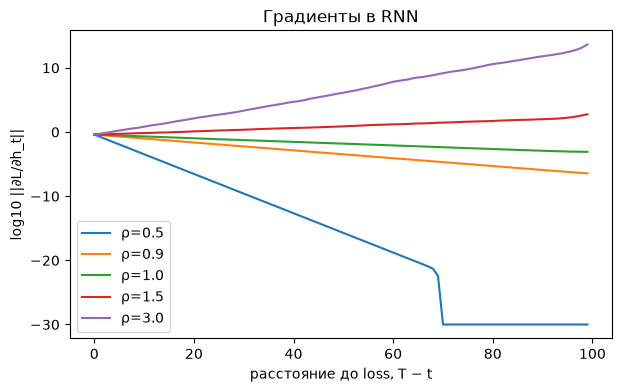

In [7]:
def grad_norms_by_distance(rho, T=100, H=128, n_seq=8):
    torch.manual_seed(0)
    Q, _ = torch.linalg.qr(torch.randn(H, H))
    Whh = (rho * Q).requires_grad_(); Wxh = torch.randn(H, V) * 0.1; Why = torch.randn(V, H) * 0.1
    ids = torch.randint(V, (n_seq, T + 1))
    # (прогоните RNN, сохраните h_t с retain_grad(), loss только на последнем шаге)
    Wxh = (torch.randn(H, V) * 0.1).requires_grad_()
    Why = torch.randn(V, H) * 0.1

    hs = []
    h = torch.zeros(n_seq, H)
    for t in range(T):
        x = F.one_hot(ids[:, t], V).float()
        h = torch.tanh(x @ Wxh.T + h @ Whh.T)
        h.retain_grad()
        hs.append(h)

    logits = hs[-1] @ Why.T
    loss = F.cross_entropy(logits, ids[:, T])
    loss.backward()

    norms = [hs[t].grad.norm().item() for t in range(T - 1, -1, -1)]
    return np.array(norms)

plt.figure(figsize=(7, 4))
for rho in [0.5, 0.9, 1.0, 1.5, 3.0]:
    g = grad_norms_by_distance(rho)
    plt.plot(np.log10(g + 1e-30), label=f"ρ={rho}")
plt.xlabel("расстояние до loss, T − t"); plt.ylabel("log10 ||∂L/∂h_t||"); plt.legend(); plt.title("Градиенты в RNN")
plt.savefig(ARTIFACTS / "lab03_grad_decay.png", dpi=120); plt.show()

## 4. RNN и LSTM языковые модели

Обучите символьные RNN и LSTM одинакового размера (embedding 64, скрытый слой 256) с truncated BPTT по 128 символов и gradient clipping. Сравните с n-граммами по кросс-энтропии на валидации. Так как корпус состоит из ASCII-символов, bits-per-character равен bits-per-byte.

In [8]:
class RNNLM(nn.Module):
    def __init__(self, V, emb=64, hidden=256, cell="lstm"):
        super().__init__()
        self.emb = nn.Embedding(V, emb)
        self.rnn = (nn.LSTM if cell == "lstm" else nn.RNN)(emb, hidden, batch_first=True)
        self.out = nn.Linear(hidden, V)
    def forward(self, x, state=None):
        y, state = self.rnn(self.emb(x), state)
        return self.out(y), state

train_ids = torch.tensor([stoi[c] for c in train_text]); val_ids = torch.tensor([stoi[c] for c in val_text])

def batch(data, T=128, B=64):
    ix = torch.randint(len(data) - T - 1, (B,))
    return torch.stack([data[i:i + T] for i in ix]).to(DEVICE), torch.stack([data[i + 1:i + T + 1] for i in ix]).to(DEVICE)

@torch.no_grad()
def eval_ce(model, data, T=256):
    model.eval(); nll, cnt, state = 0.0, 0, None
    for i in range(0, len(data) - 1 - T, T):
        x, y = data[i:i + T][None].to(DEVICE), data[i + 1:i + T + 1][None].to(DEVICE)
        logits, state = model(x, state)
        nll += F.cross_entropy(logits[0], y[0], reduction="sum").item(); cnt += T
    model.train(); return nll / cnt

def train_rnn(cell, steps):
    set_seed(); model = RNNLM(V, cell=cell).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3 if cell == "lstm" else 1e-3)
    # TODO: ваш код (стандартный цикл: batch → loss → backward → clip_grad_norm_(1.0) → step)
    T, B = 128, 64
    model.train()
    for step in range(steps):
        x, y = batch(train_ids, T=T, B=B)
        logits, _ = model(x)
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if step % 50 == 0 or step == steps - 1:
            print(f"  [{cell}] step {step:4d}  loss={loss.item():.3f}")
    return model

STEPS = 300 if FAST_DEV_RUN else 5000
models = {}
for cell in ("rnn", "lstm"):
    t0 = time.time(); models[cell] = train_rnn(cell, STEPS)
    print(cell, f"{time.time() - t0:.0f} c")

e:\temp\llm\.venv\Lib\site-packages\torch\nn\modules\module.py:1369: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:39.)
  return t.to(


  [rnn] step    0  loss=4.174
  [rnn] step   50  loss=2.489
  [rnn] step  100  loss=2.265
  [rnn] step  150  loss=2.100
  [rnn] step  200  loss=2.004
  [rnn] step  250  loss=1.975
  [rnn] step  299  loss=1.853
rnn 4 c
  [lstm] step    0  loss=4.167
  [lstm] step   50  loss=2.267
  [lstm] step  100  loss=2.013
  [lstm] step  150  loss=1.883
  [lstm] step  200  loss=1.737
  [lstm] step  250  loss=1.707
  [lstm] step  299  loss=1.635
lstm 5 c


In [9]:
import pandas as pd
rows = [{"модель": f"{k}-gram KN", "CE (нат)": v} for k, v in ngram_res.items()]
rows += [{"модель": c.upper(), "CE (нат)": eval_ce(m, val_ids)} for c, m in models.items()]
df = pd.DataFrame(rows); df["perplexity"] = np.exp(df["CE (нат)"]); df["bpb"] = df["CE (нат)"] / math.log(2)
df.round(3)

,модель,CE (нат),perplexity,bpb
0,2-gram KN,2.492,12.088,3.596
1,3-gram KN,1.985,7.276,2.863
2,4-gram KN,1.662,5.268,2.397
3,5-gram KN,1.498,4.472,2.161
4,RNN,1.957,7.078,2.823
5,LSTM,1.739,5.691,2.509


## 5. Температура и энтропия

Для LSTM посчитайте среднюю энтропию распределения $\mathrm{softmax}(z/T)$ на валидационных позициях при $T \in [0.1, 3]$ и сгенерируйте по 200 символов при $T = 0.3, 1.0, 1.5$. Покажите аналитически, что при $T\to 0$ энтропия стремится к $0$ (при единственном максимуме), а при $T \to \infty$ — к $\log|V|$.


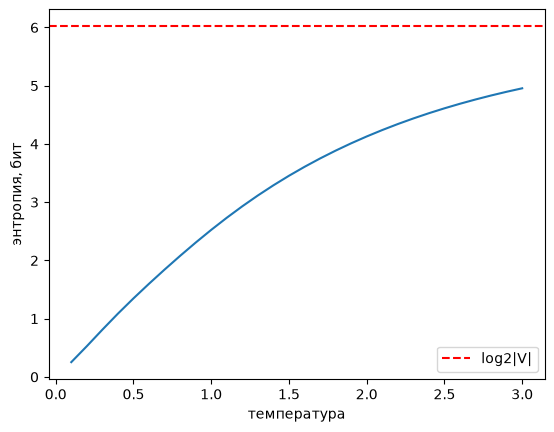

--- T=0.3
ROMEO:
The searn the prownot that do the man the word,
The promion and that will not the more the well.

KING RICHARD III:
So make the more the pray the grace, and her man the grace.

BUCKINGHAM:
I would th

--- T=1.0
ROMEO:
He wilt we as yess thee? To thee?

PRICIS:
Yiest a bey a Bovint--for it destrust
Marth brother to a time to blore,
We balk,--
pelement he of so, my luss.

COLIFLOM:
I wilt than the surfore insto
To I

--- T=1.5
ROMEO:
An amnowe,
Bvoy Yol:
Ked Doreasy Varry AFare.
Whiras sostiluce! I marh ake 'seals, Wask dutpintide.
Anse.

KING RICHEbS I RICoSI CroDad
casisy.
Thy dburs,
Strock-say;Ullns?:
AVar;.
Your vefSey;
Messt



In [12]:
@torch.no_grad()
def mean_entropy(model, data, temps, T=256, n_chunks=10):
    model.eval()
    logits_all, state = [], None
    limit = min(len(data) - 1 - T, n_chunks * T)
    for i in range(0, limit, T):
        x = data[i:i + T][None].to(DEVICE)
        logits, state = model(x, state)
        logits_all.append(logits[0])
    logits_all = torch.cat(logits_all, dim=0)   # (L, V)

    entropies = []
    for temp in temps:
        p = F.softmax(logits_all / temp, dim=-1)
        H = -(p * torch.log(p + 1e-30)).sum(-1).mean().item()
        entropies.append(H)
    model.train()
    return np.array(entropies)

temps = np.linspace(0.1, 3, 30)
H = mean_entropy(models["lstm"], val_ids, temps)
plt.plot(temps, H / math.log(2)); plt.axhline(math.log2(V), ls="--", c="r", label="log2|V|")
plt.xlabel("температура"); plt.ylabel("энтропия, бит"); plt.legend(); plt.show()

@torch.no_grad()
def sample(model, prompt, n=200, temp=1.0):
    model.eval(); ids = torch.tensor([[stoi[c] for c in prompt]], device=DEVICE)
    logits, state = model(ids); out = list(prompt)
    for _ in range(n):
        nxt = torch.multinomial(F.softmax(logits[0, -1] / temp, -1), 1)
        out.append(chars[nxt.item()]); logits, state = model(nxt[None], state)
    return "".join(out)

for t in (0.3, 1.0, 1.5):
    print(f"--- T={t}\n{sample(models['lstm'], 'ROMEO:', temp=t)}\n")

## Вопросы

1. Почему в KN для младших порядков используются счётчики продолжения, а не обычные частоты? Приведите пример («Francisco»).
2. По графику из п. 3 оцените эффективную длину памяти RNN при \(\rho = 0.9\). Почему при \(\rho > 1\) градиенты всё равно не растут неограниченно?
3. Как вентили LSTM меняют произведение якобианов? Почему ячейка \(c_t\) с forget gate, близким к 1, решает проблему затухания?
4. Почему gradient clipping помогает при взрыве, но не при затухании градиентов?
5. Чем ограничена максимальная perplexity n-граммной модели при росте \(n\) на фиксированном корпусе?

Выводы: была построена символьная n-граммная модель Кнезера–Нея, вручную реализован обратный проход для одного шага RNN и обучены RNN и LSTM для сравнения с n-граммами. Ручной обратный проход полностью совпал с autograd. KN улучшает perplexity, LSTM показала себя лучше RNN, но 5-gram KN показала самые лучшие результаты.